# UTS GRAF SAINS DATA

**Nama:** Thea Bayu Revalina  

**NIM:** 23031554035
  
**Kelas:** 2023A

## 1.1 Persiapan dan Perkenalan Lingkungan

1. Buatlah sebuah environment baru menggunakan venv atau uv dan jalankan perintah seperti berikut

$ python -m venv myenv

2. Matikan paket virtual environment yang lain (jika ada).

$ source myvenv/bin/activate

3. Install dependensi paket-paket seperti yang ada di dalam file requirements.txt seperti berikut

pip install -r requirements.txt

## 1.2 Mempelajari Penggunaan Driver Neo4J

In [1]:

from neo4j import GraphDatabase, RoutingControl

# 1. Konfigurasi koneksi Neo4j
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin123")  


# 2. Membuat node Person dan relationship KNOWS
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


# 3. Membaca daftar teman seseorang
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend.name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    print(f"\nDaftar teman dari {name}:")
    if not records:
        print("Tidak ada teman yang ditemukan.")
    else:
        for record in records:
            print(record["friend_name"])


# 4. Menampilkan seluruh node Person
def print_people(driver):
    records, _, _ = driver.execute_query(
        """
        MATCH (p:Person)
        RETURN p.name AS name
        ORDER BY name
        """,
        database_="neo4j",
    )

    print("\nSeluruh node Person:")
    for record in records:
        print(record["name"])


# 5. Menampilkan seluruh relationship KNOWS
def print_relationships(driver):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(b:Person)
        RETURN a.name AS person, b.name AS friend
        ORDER BY person, friend
        """,
        database_="neo4j",
    )

    print("\nSeluruh relationship KNOWS:")
    for record in records:
        print(f'{record["person"]} -> {record["friend"]}')


# 6. Menjalankan program
def main():
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        # Memeriksa koneksi
        driver.verify_connectivity()
        print("Koneksi ke Neo4j berhasil!")

        # Membuat data pertemanan
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")

        # Membaca data
        print_friends(driver, "Arthur")
        print_people(driver)
        print_relationships(driver)


if __name__ == "__main__":
    main()


Koneksi ke Neo4j berhasil!

Daftar teman dari Arthur:
Guinevere
Lancelot
Merlin

Seluruh node Person:
Arthur
Guinevere
Lancelot
Merlin

Seluruh relationship KNOWS:
Arthur -> Guinevere
Arthur -> Lancelot
Arthur -> Merlin


In [21]:

from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin123")

QUERY = """
MATCH (n)
CALL {
    WITH n
    DETACH DELETE n
} IN TRANSACTIONS OF 1000 ROWS
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    # execute_query menggunakan transaksi eksplisit secara default.
    # CALL ... IN TRANSACTIONS harus dijalankan dalam implicit transaction.
    with driver.session(database="neo4j") as session:
        result = session.run(QUERY)
        summary = result.consume()

        print("Penghapusan selesai.")
        print("Ringkasan:", summary.counters)

print("Seluruh node dan relationship telah dihapus.")


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=1, offset=11>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 11, 'line': 3, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (n)\nCALL {\n    WITH n\n    DETACH DELETE n\n} IN TRANSACTIONS OF 1000 ROWS\n'


Penghapusan selesai.
Ringkasan: SummaryCounters{nodes_deleted: 1642641, relationships_deleted: 2964101, contains_updates: True, contains_system_updates: False}
Seluruh node dan relationship telah dihapus.


In [22]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin123")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    result = driver.execute_query(
        "MATCH (n) RETURN count(n) AS jumlah_node",
        database_="neo4j",
    )
    print("Jumlah node tersisa:", result.records[0]["jumlah_node"])

Jumlah node tersisa: 0


1. Apa nama database yang digunakan pada tutorial ini?

In [32]:
# Memeriksa database default Neo4j
with driver.session(database="system") as session:
    result = session.run("""
        SHOW DEFAULT DATABASE
        YIELD name
        RETURN name AS database_default
    """)

    for record in result:
        print("Database default:", record["database_default"])

Database default: neo4j


In [33]:
from neo4j import GraphDatabase
from IPython.display import display
import pandas as pd

def cypher(query, db="neo4j"):
    with driver.session(database=db) as session:
        result = session.run(query)
        records = [record.data() for record in result]
        return pd.DataFrame(records)

display(cypher(
    "SHOW DATABASES YIELD name, currentStatus, default "
    "RETURN name, currentStatus, default",
    db="system"
))

,name,currentStatus,default
0,graftugas,online,False
1,neo4j,online,True
2,system,online,False


2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!

Database Neo4j dapat diakses menggunakan bahasa query **Cypher** melalui Neo4j Browser atau Neo4j Driver pada Python. Beberapa sintaks Cypher yang dapat digunakan antara lain:

| Perintah Cypher | Keterangan |
|---|---|
| `CREATE` | Membuat node atau relationship. |
| `MATCH` | Mencari dan membaca data. |
| `MERGE` | Membuat node atau relationship jika belum tersedia. |
| `SET` | Menambahkan atau mengubah properti. |
| `DELETE` | Menghapus relationship atau node. |
| `DETACH DELETE` | Menghapus node beserta relationship yang terhubung. |

Untuk mengakses database lain dalam satu instance, nama database dapat ditentukan melalui parameter `database_` pada driver Python, misalnya `database_="nama_database_lain"`, dengan syarat database tersebut tersedia dan pengguna memiliki izin akses.

3. Apa jenis graf pertemanan yang telah dibuat di sini?

Graf pertemanan yang dibuat merupakan **graf berarah (*directed graph*)**, karena relationship `KNOWS` memiliki arah dari satu node `Person` ke node `Person` lainnya.

Contohnya, `(Arthur)-[:KNOWS]->(Merlin)` menunjukkan bahwa Arthur mengenal Merlin. Hubungan tersebut tidak otomatis berarti Merlin mengenal Arthur, karena relationship yang dibuat hanya mengarah dari Arthur ke Merlin.

## 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

1. Unduh data dari Kaggle dengan perintah berikut:

Windows PowerShell:

curl.exe -L -o ecommerce-dataset.zip `
ω→ https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

2. Perhatikan fitur yang telah diunduh dengan rincian sebagai berikut:

| Fitur | Keterangan |
|---|---|
| `timestamp` | Waktu event dalam Unix epoch milidetik |
| `visitorid` | ID unik pengunjung |
| `event` | Jenis interaksi: `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk |
| `transactionid` | ID transaksi, hanya terisi untuk event `transaction` |


3. Buatlah mekanisme pembuatan session Neo4J baru dengan perintah kurang lebih seperti berikut (sumber:
Neo4J Driver 6.4).

In [23]:
import os
import sys
import argparse
import pandas as pd

from neo4j import GraphDatabase
from tqdm.auto import tqdm

# Konfigurasi Neo4j
uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "admin123"  

# Membuat driver
driver = GraphDatabase.driver(
    uri,
    auth=(user, password)
)

# Memeriksa koneksi
driver.verify_connectivity()

print("Koneksi ke Neo4j berhasil.")

# Membuat session
session = driver.session(database="system")

print("Session Neo4j berhasil dibuat.")

Koneksi ke Neo4j berhasil.
Session Neo4j berhasil dibuat.


In [24]:
session.close()

session = driver.session(database="neo4j")
print("Session database neo4j berhasil dibuat.")

Session database neo4j berhasil dibuat.


In [25]:
# Konfigurasi argumen secara langsung
class Args:
    user = "neo4j"
    password = "admin123"
    bolt = "neo4j://127.0.0.1:7687"
    source = r"C:\UTS-GrafSainsData\data"

args = Args()

# Memeriksa keberadaan CSV
csv_file_path = os.path.join(
    args.source,
    "events.csv"
)

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File '{csv_file_path}' tidak ditemukan!"
    )

print(f"File dataset ditemukan: {csv_file_path}")

File dataset ditemukan: C:\UTS-GrafSainsData\data\events.csv


In [26]:
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket ke Neo4j."
    )

    parser.add_argument(
        "-u", "--user",
        default="neo4j"
    )
    parser.add_argument(
        "-p", "--password",
        default="neo4j"
    )
    parser.add_argument(
        "-b", "--bolt",
        default="neo4j://127.0.0.1:7687"
    )
    parser.add_argument(
        "-s", "--source",
        default="data"
    )

    return parser.parse_args()

In [27]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

    print("Constraint Visitor dan Item berhasil dibuat.")

with driver.session(database="neo4j") as session:
    create_constraints(session)

Constraint Visitor dan Item berhasil dibuat.


4. Anda lanjutkan dengan proses impor dengan mekanisme batch, kurang lebih sebagai berikut:

In [28]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {
        visitorId: toInteger(row.visitorid)
    })

    MERGE (i:Item {
        itemId: toInteger(row.itemid)
    })

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'

        CREATE (v)-[:VIEWED {
            timestamp: toInteger(row.timestamp)
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'

        CREATE (v)-[:ADDED_TO_CART {
            timestamp: toInteger(row.timestamp)
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'

        CREATE (v)-[:BOUGHT {
            timestamp: toInteger(row.timestamp),
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(
        cypher_query,
        batch=batch
    ).consume()

In [29]:
batch_size = 1000

# Menghitung total baris untuk progress bar
total_rows = sum(
    len(chunk)
    for chunk in pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )
)

total_chunks = (total_rows + batch_size - 1) // batch_size

print(f"Total baris data: {total_rows:,}")
print(f"Total batch: {total_chunks:,}")

# Membuat session untuk database neo4j
with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        # Membersihkan transactionid yang kosong
        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )

        # Menghapus data yang tidak memiliki ID penting
        chunk = chunk.dropna(
            subset=[
                "visitorid",
                "itemid",
                "timestamp",
                "event"
            ]
        )

        records = chunk.to_dict(
            orient="records"
        )

        if records:
            session.execute_write(
                import_batch,
                records
            )

print("Proses impor berhasil.")

Total baris data: 2,756,101
Total batch: 2,757
Constraint Visitor dan Item berhasil dibuat.
Membaca file data dari: C:\UTS-GrafSainsData\data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/2757 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=14, column=5, offset=192>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 192, 'line': 14, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {\n        visitorId: toInteger(row.visitorid)\n    })\n\n    MERGE (i:Item {\n        itemId: toInteger(row.itemid)\n    })\n\n    WITH v, i, row\n\n    CALL {\n        WITH v, i, row\n        WITH v, i, row\n        WHERE row.event = 'view'\n\n        CREATE (v)-[:VIEWED {\n    

Proses impor berhasil.


In [30]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS Label, count(n) AS Jumlah
    """)

    for record in result:
        print(record["Label"], record["Jumlah"])

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
    """)

    for record in result:
        print(record["Jenis_Relasi"], record["Jumlah"])

['Visitor'] 1407580
['Item'] 235061
VIEWED 2664312
ADDED_TO_CART 69332
BOUGHT 22457


## 2.1 WRANGLING DAN EDA 

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas.
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024. 

Jawab : 

Periode yang digunakan : 

*   P1: 2015-05-05 sampai sebelum 2015-06-05
*   P2: 2015-08-05 sampai sebelum 2015-09-05

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [7]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("data/events.csv")

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms"
)

train = df[
    (df["datetime"] >= "2015-05-05") &
    (df["datetime"] < "2015-06-05")
].copy()

test = df[
    (df["datetime"] >= "2015-08-05") &
    (df["datetime"] < "2015-09-05")
].copy()

Path("output").mkdir(parents=True, exist_ok=True)

train.to_csv("output/train.csv", index=False)
test.to_csv("output/test.csv", index=False)

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))
print("\nPeriode training:")
print(train["datetime"].min(), "sampai", train["datetime"].max())
print("\nPeriode testing:")
print(test["datetime"].min(), "sampai", test["datetime"].max())

Jumlah data training: 650875
Jumlah data testing: 551670

Periode training:
2015-05-05 00:00:01.627000 sampai 2015-06-04 23:59:56.235000

Periode testing:
2015-08-05 00:00:00.700000 sampai 2015-09-04 23:59:59.493000


**Penjelasan:** 

Tahap persiapan data diawali dengan mengubah kolom timestamp dari format Unix dalam satuan milidetik menjadi format tanggal menggunakan fungsi pd.to_datetime(). Setelah itu, data disaring berdasarkan dua rentang waktu yang telah ditentukan. Data hasil penyaringan pada periode pertama disimpan ke dalam file output/train.csv, sedangkan data pada periode kedua disimpan ke dalam file output/test.csv menggunakan fungsi to_csv().

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [8]:
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "admin123"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

queries = {
    "Visitor": """
        MATCH (v:Visitor)
        RETURN count(v) AS jumlah
    """,
    "Item": """
        MATCH (i:Item)
        RETURN count(i) AS jumlah
    """,
    "VIEWED": """
        MATCH (:Visitor)-[r:VIEWED]->(:Item)
        RETURN count(r) AS jumlah
    """,
    "ADDED_TO_CART": """
        MATCH (:Visitor)-[r:ADDED_TO_CART]->(:Item)
        RETURN count(r) AS jumlah
    """,
    "BOUGHT": """
        MATCH (:Visitor)-[r:BOUGHT]->(:Item)
        RETURN count(r) AS jumlah
    """
}

hasil = {}

try:
    with driver.session() as session:
        for nama, query in queries.items():
            record = session.run(query).single()
            hasil[nama] = record["jumlah"]
finally:
    driver.close()

hasil["Total relasi interaksi"] = (
    hasil["VIEWED"]
    + hasil["ADDED_TO_CART"]
    + hasil["BOUGHT"]
)

tabel_hasil = pd.DataFrame(
    list(hasil.items()),
    columns=["Komponen", "Jumlah"]
)

display(tabel_hasil)

,Komponen,Jumlah
0,Visitor,1407580
1,Item,235061
2,VIEWED,2664312
3,ADDED_TO_CART,69332
4,BOUGHT,22457
5,Total relasi interaksi,2756101


**Penjelasan:** 

Subgraph terdiri atas dua jenis simpul, yaitu Visitor dan Item, serta tiga jenis relasi, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Python API digunakan untuk menjalankan query Cypher melalui Neo4j Driver, mengambil nilai jumlah setiap komponen, dan menyajikannya dalam tabel. Cypher menggunakan pola MATCH untuk menemukan node atau relasi, sedangkan fungsi count() digunakan untuk menghitung jumlah elemen yang sesuai.


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [9]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix, save_npz

train = pd.read_csv("output/train.csv")

interaksi = train[["visitorid", "itemid"]].drop_duplicates()

visitor_ids = np.sort(interaksi["visitorid"].unique())
item_ids = np.sort(interaksi["itemid"].unique())

visitor_to_idx = {
    visitor_id: idx
    for idx, visitor_id in enumerate(visitor_ids)
}

item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

rows = interaksi["visitorid"].map(visitor_to_idx).to_numpy()
cols = interaksi["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(interaksi), dtype=np.float32)

vsm_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

save_npz("output/vsm_visitor_item.npz", vsm_user)

pd.DataFrame({"visitorid": visitor_ids}).to_csv(
    "output/visitor_index.csv", index=False
)

pd.DataFrame({"itemid": item_ids}).to_csv(
    "output/item_index.csv", index=False
)

print("Shape VSM User:", vsm_user.shape)
print("Jumlah nilai nonzero:", vsm_user.nnz)
print("Jumlah Visitor:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Sparsity:", 1 - vsm_user.nnz /
      (vsm_user.shape[0] * vsm_user.shape[1]))

Shape VSM User: (337107, 120675)
Jumlah nilai nonzero: 505238
Jumlah Visitor: 337107
Jumlah Item: 120675
Sparsity: 0.9999875803050446


In [10]:
jumlah_sel = vsm_user.shape[0] * vsm_user.shape[1]
sparsity = 1 - (vsm_user.nnz / jumlah_sel)

print("Dimensi matriks:", vsm_user.ndim)
print("Shape:", vsm_user.shape)
print("Jumlah baris:", vsm_user.shape[0])
print("Jumlah kolom:", vsm_user.shape[1])
print("Jumlah interaksi nonzero:", vsm_user.nnz)
print("Sparsity:", f"{sparsity:.6%}")

Dimensi matriks: 2
Shape: (337107, 120675)
Jumlah baris: 337107
Jumlah kolom: 120675
Jumlah interaksi nonzero: 505238
Sparsity: 99.998758%


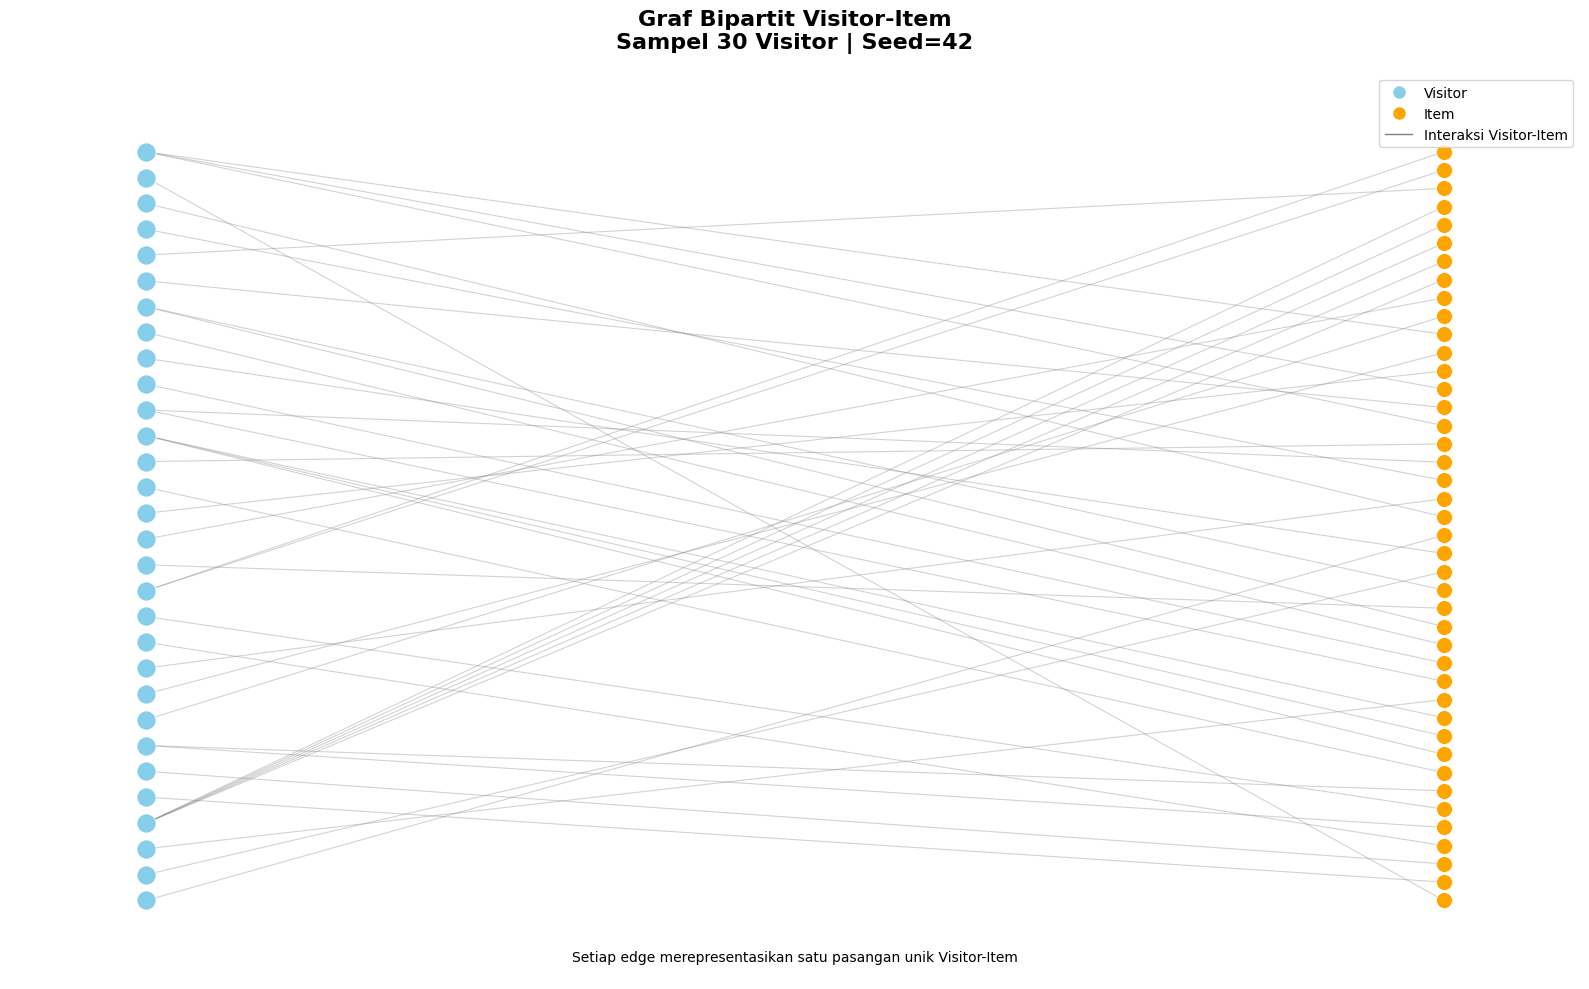

Jumlah Visitor sampel : 30
Jumlah Item           : 42
Jumlah edge unik      : 42
Jumlah seluruh node   : 72
Apakah graf bipartit? : True


In [11]:

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# 1. Pilih maksimal 30 Visitor secara acak dan reproducible
SEED = 42
rng = np.random.default_rng(SEED)

visitor_tersedia = interaksi["visitorid"].dropna().unique()
jumlah_visitor_plot = min(30, len(visitor_tersedia))

sample_visitors = rng.choice(
    visitor_tersedia,
    size=jumlah_visitor_plot,
    replace=False
)

# 2. Ambil pasangan Visitor-Item dari sampel
sample_edges = (
    interaksi.loc[
        interaksi["visitorid"].isin(sample_visitors),
        ["visitorid", "itemid"]
    ]
    .dropna()
    .drop_duplicates()
)

# 3. Buat graf bipartit
G_user = nx.Graph()

for visitor_id in sample_visitors:
    G_user.add_node(
        f"U{visitor_id}",
        node_type="Visitor",
        bipartite=0
    )

for row in sample_edges.itertuples(index=False):
    visitor_node = f"U{row.visitorid}"
    item_node = f"I{row.itemid}"

    G_user.add_node(
        item_node,
        node_type="Item",
        bipartite=1
    )
    G_user.add_edge(visitor_node, item_node)

# 4. Kelompokkan node
visitor_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "Visitor"
]

item_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "Item"
]

# 5. Layout dua kelompok
pos = nx.bipartite_layout(
    G_user,
    visitor_nodes,
    align="vertical",
    scale=2
)

# 6. Visualisasi
fig, ax = plt.subplots(figsize=(16, 10))

nx.draw_networkx_edges(
    G_user, pos,
    ax=ax,
    edge_color="gray",
    width=0.8,
    alpha=0.35
)

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=visitor_nodes,
    node_color="skyblue",
    node_size=190,
    edgecolors="white",
    linewidths=0.6,
    ax=ax
)

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=130,
    edgecolors="white",
    linewidths=0.5,
    ax=ax
)

legend_elements = [
    Line2D(
        [0], [0], marker="o", color="w",
        label="Visitor", markerfacecolor="skyblue",
        markeredgecolor="white", markersize=10
    ),
    Line2D(
        [0], [0], marker="o", color="w",
        label="Item", markerfacecolor="orange",
        markeredgecolor="white", markersize=10
    ),
    Line2D(
        [0], [0], color="gray", linewidth=1,
        label="Interaksi Visitor-Item"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True
)

ax.set_title(
    f"Graf Bipartit Visitor-Item\n"
    f"Sampel {len(visitor_nodes)} Visitor | Seed={SEED}",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.text(
    0.5, 0.02,
    "Setiap edge merepresentasikan satu pasangan unik Visitor-Item",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.axis("off")
plt.tight_layout()
plt.show()

# 7. Statistik graf
print("Jumlah Visitor sampel :", len(visitor_nodes))
print("Jumlah Item           :", len(item_nodes))
print("Jumlah edge unik      :", G_user.number_of_edges())
print("Jumlah seluruh node   :", G_user.number_of_nodes())
print("Apakah graf bipartit? :", nx.is_bipartite(G_user))


**Penjelasan:** 

VSM User dibentuk dengan menempatkan Visitor sebagai baris dan Item sebagai kolom. Nilai matriks bernilai 1 apabila terdapat interaksi antara pengguna dan item, serta 0 apabila tidak terdapat interaksi. Matriks disimpan dalam format sparse CSR karena mayoritas kombinasi pengguna dan item tidak memiliki interaksi. Visualisasi NetworkX menggunakan sebagian kecil node untuk memperlihatkan struktur hubungan Visitor-Item tanpa membebani memori.

5. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [12]:
from scipy.sparse import load_npz, save_npz

vsm_user = load_npz("output/vsm_visitor_item.npz")

vsm_item = vsm_user.T.tocsr()

save_npz("output/vsm_item_visitor.npz", vsm_item)

print("Dimensi VSM Item:", vsm_item.ndim)
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah nilai nonzero:", vsm_item.nnz)

jumlah_sel_item = vsm_item.shape[0] * vsm_item.shape[1]
sparsity_item = 1 - vsm_item.nnz / jumlah_sel_item

print("Sparsity:", f"{sparsity_item:.6%}")

Dimensi VSM Item: 2
Shape VSM Item: (120675, 337107)
Jumlah nilai nonzero: 505238
Sparsity: 99.998758%


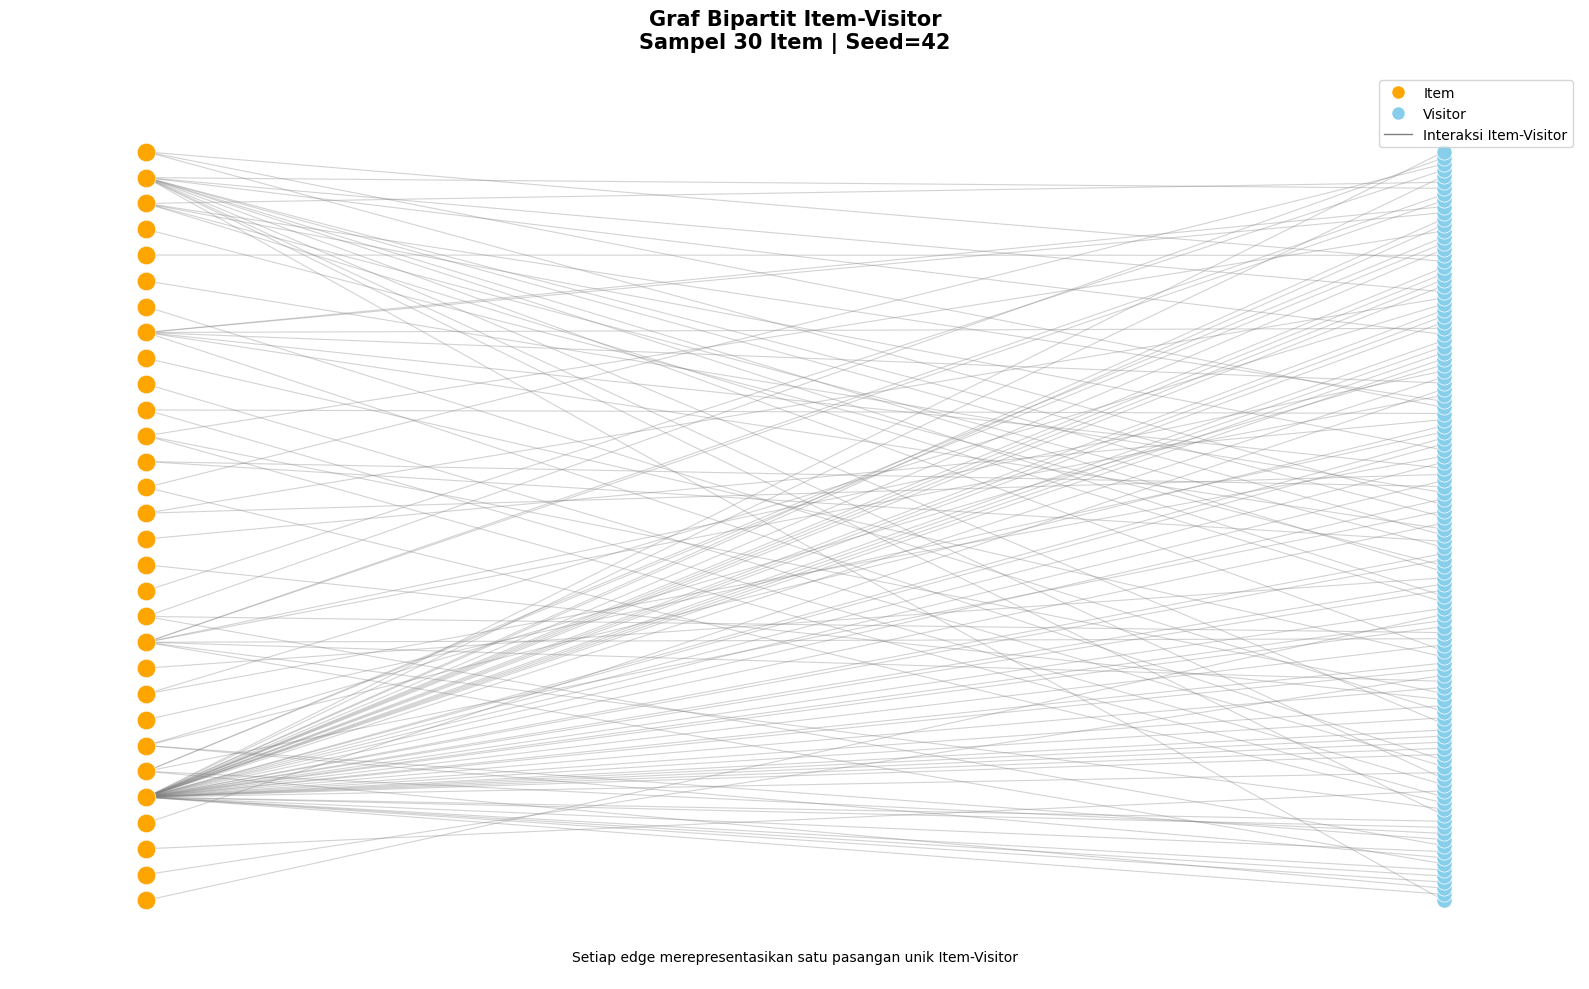

Jumlah Item sampel : 30
Jumlah Visitor      : 124
Jumlah edge unik    : 124
Jumlah seluruh node : 154
Apakah graf bipartit?: True


In [13]:

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# 1. Ambil maksimal 30 Item secara acak
SEED = 42
rng = np.random.default_rng(SEED)

item_tersedia = interaksi["itemid"].dropna().unique()
jumlah_item_plot = min(30, len(item_tersedia))

sample_items = rng.choice(
    item_tersedia,
    size=jumlah_item_plot,
    replace=False
)

# 2. Ambil interaksi yang melibatkan Item sampel
sample_edges_item = (
    interaksi.loc[
        interaksi["itemid"].isin(sample_items),
        ["visitorid", "itemid"]
    ]
    .dropna()
    .drop_duplicates()
)

# 3. Buat graf bipartit Item-Visitor
G_item = nx.Graph()

# Tambahkan node Item
for item_id in sample_items:
    G_item.add_node(
        f"I{item_id}",
        node_type="Item",
        bipartite=0
    )

# Tambahkan node Visitor dan edge
for row in sample_edges_item.itertuples(index=False):
    item_node = f"I{row.itemid}"
    visitor_node = f"U{row.visitorid}"

    G_item.add_node(
        visitor_node,
        node_type="Visitor",
        bipartite=1
    )

    G_item.add_edge(item_node, visitor_node)

# 4. Pisahkan node berdasarkan jenis
item_nodes = [
    n for n, data in G_item.nodes(data=True)
    if data["node_type"] == "Item"
]

visitor_nodes = [
    n for n, data in G_item.nodes(data=True)
    if data["node_type"] == "Visitor"
]

# 5. Atur posisi node
pos = nx.bipartite_layout(
    G_item,
    item_nodes,
    align="vertical",
    scale=2
)

# 6. Gambar graf
fig, ax = plt.subplots(figsize=(16, 10))

nx.draw_networkx_edges(
    G_item,
    pos,
    ax=ax,
    edge_color="gray",
    width=0.8,
    alpha=0.35
)

nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=180,
    edgecolors="white",
    linewidths=0.5,
    ax=ax
)

nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=visitor_nodes,
    node_color="skyblue",
    node_size=120,
    edgecolors="white",
    linewidths=0.5,
    ax=ax
)

# 7. Legenda
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Item",
        markerfacecolor="orange",
        markeredgecolor="white",
        markersize=10
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Visitor",
        markerfacecolor="skyblue",
        markeredgecolor="white",
        markersize=10
    ),
    Line2D(
        [0], [0],
        color="gray",
        linewidth=1,
        label="Interaksi Item-Visitor"
    )
]

ax.legend(handles=legend_elements, loc="upper right")
ax.set_title(
    f"Graf Bipartit Item-Visitor\n"
    f"Sampel {len(item_nodes)} Item | Seed={SEED}",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.text(
    0.5, 0.02,
    "Setiap edge merepresentasikan satu pasangan unik Item-Visitor",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.axis("off")
plt.tight_layout()
plt.show()

# 8. Informasi graf untuk laporan
print("Jumlah Item sampel :", len(item_nodes))
print("Jumlah Visitor      :", len(visitor_nodes))
print("Jumlah edge unik    :", G_item.number_of_edges())
print("Jumlah seluruh node :", G_item.number_of_nodes())
print("Apakah graf bipartit?:", nx.is_bipartite(G_item))


**Penjelasan:** 

VSM Item diperoleh melalui proses transpose matriks User-Item, sehingga baris merepresentasikan item dan kolom merepresentasikan visitor. Dengan struktur tersebut, setiap item digambarkan berdasarkan pola interaksi pengguna yang berhubungan dengannya. Jumlah elemen bernilai nonzero tetap sama seperti pada VSM User, namun posisi dimensi baris dan kolom saling bertukar.

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [14]:
from scipy.sparse import load_npz

vsm_user = load_npz("output/vsm_visitor_item.npz")
vsm_item = vsm_user.T.tocsr()

perbandingan = {
    "VSM User": {
        "shape": vsm_user.shape,
        "nnz": vsm_user.nnz,
        "jumlah_sel": vsm_user.shape[0] * vsm_user.shape[1]
    },
    "VSM Item": {
        "shape": vsm_item.shape,
        "nnz": vsm_item.nnz,
        "jumlah_sel": vsm_item.shape[0] * vsm_item.shape[1]
    }
}

for nama, data in perbandingan.items():
    print(nama)
    print("  Shape:", data["shape"])
    print("  Nonzero:", data["nnz"])
    print("  Jumlah sel:", data["jumlah_sel"])

VSM User
  Shape: (337107, 120675)
  Nonzero: 505238
  Jumlah sel: 40680387225
VSM Item
  Shape: (120675, 337107)
  Nonzero: 505238
  Jumlah sel: 40680387225


**Penjelasan:** 

VSM Item memiliki jumlah baris yang lebih sedikit dibandingkan VSM User karena jumlah item yang tersedia lebih kecil daripada jumlah visitor. Konsekuensinya, matriks kemiripan (similarity matrix) Item-Item yang dihasilkan juga berukuran lebih kecil. Meskipun demikian, VSM User dan VSM Item tetap memiliki jumlah elemen nonzero yang identik karena keduanya merupakan hasil transposisi satu sama lain. Dari sisi komputasi, efisiensi perhitungan kemiripan tidak hanya ditentukan oleh ukuran matriks, tetapi juga dipengaruhi oleh tingkat sparsity, pola distribusi interaksi, serta banyaknya pasangan entitas yang harus dibandingkan.

Pada implementasi rekomendasi berbasis K-Nearest Neighbors (KNN), proyeksi User-User dipilih karena tujuan utama sistem adalah mengidentifikasi pengguna yang memiliki karakteristik atau pola interaksi serupa. Tetangga terdekat yang diperoleh kemudian dimanfaatkan untuk merekomendasikan item yang belum pernah diakses oleh pengguna target. Sebaliknya, untuk skenario rekomendasi yang berfokus pada kemiripan antarproduk, proyeksi Item-Item merupakan pendekatan yang lebih tepat karena rekomendasi dihasilkan berdasarkan kesamaan karakteristik atau pola konsumsi antaritem.

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-
nakan Python
(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!
(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!


In [15]:
import pandas as pd
import numpy as np
from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity

vsm_user = load_npz("output/vsm_visitor_item.npz")
visitor_index = pd.read_csv("output/visitor_index.csv")

visitor_ids = visitor_index["visitorid"].to_numpy()

reference_visitor = 114354

posisi = np.where(visitor_ids == reference_visitor)[0]

if len(posisi) == 0:
    raise ValueError(
        f"Visitor {reference_visitor} tidak ditemukan pada VSM."
    )

reference_idx = posisi[0]

similarities = cosine_similarity(
    vsm_user[reference_idx],
    vsm_user
).ravel()

similarities[reference_idx] = -1

top5_idx = np.argsort(similarities)[::-1][:5]

hasil_similarity = pd.DataFrame({
    "reference_visitor": reference_visitor,
    "visitorid": visitor_ids[top5_idx],
    "similarity": similarities[top5_idx]
})

print(hasil_similarity)
hasil_similarity.to_csv(
    "output/top5_similarity.csv",
    index=False
)

   reference_visitor  visitorid  similarity
0             114354    1037191    0.530330
1             114354     863545    0.500000
2             114354    1401634    0.353553
3             114354    1336418    0.353553
4             114354    1060091    0.353553


**Query Neo4j:** 

MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(tetangga:Visitor)
RETURN
    v.visitorid AS visitor_acuan,
    tetangga.visitorid AS visitor_mirip,
    r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5;

In [16]:
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "admin123"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

hasil_similarity = pd.read_csv(
    "output/top5_similarity.csv"
)

data = [
    {
        "reference_visitor": int(row.reference_visitor),
        "visitorid": int(row.visitorid),
        "similarity": float(row.similarity)
    }
    for row in hasil_similarity.itertuples(index=False)
]

query = """
UNWIND $data AS d
MATCH (v:Visitor {visitorid: d.reference_visitor})
MATCH (n:Visitor {visitorid: d.visitorid})
MERGE (v)-[r:SIMILAR_TO]->(n)
SET r.similarity = d.similarity
"""

try:
    with driver.session() as session:
        result = session.run(query, data=data)
        result.consume()
finally:
    driver.close()

print("Relasi similarity berhasil diproses.")

Relasi similarity berhasil diproses.


**Query Neo4j:** 

MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(n:Visitor)
RETURN
    v.visitorid AS visitor_acuan,
    n.visitorid AS visitor_mirip,
    r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5;

**Penjelasan:** 
 
Perhitungan similarity dilakukan menggunakan cosine similarity terhadap vektor interaksi setiap Visitor. Lima Visitor dengan nilai similarity tertinggi terhadap Visitor acuan dipilih sebagai hasil analisis. Nilai tersebut kemudian disimpan pada relasi SIMILAR_TO dalam Neo4j menggunakan properti similarity. Query Cypher digunakan untuk memverifikasi bahwa nilai similarity tersimpan dan dapat diurutkan dari yang tertinggi.

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

**Query Neo4j:**

MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, i
LIMIT 100;

MATCH (v:Visitor {visitorid: 114354})-[r]->(i:Item)
RETURN v, r, i;

MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(n:Visitor)
RETURN v, r, n
ORDER BY r.similarity DESC
LIMIT 5;

MATCH (v:Visitor {visitorid: 114354})
OPTIONAL MATCH (v)-[interaksi]->(i:Item)
WHERE type(interaksi) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
OPTIONAL MATCH (v)-[sim:SIMILAR_TO]->(n:Visitor)
RETURN v, interaksi, i, sim, n
LIMIT 100;

MATCH (:Visitor)-[r:SIMILAR_TO]->(:Visitor)
RETURN count(r) AS jumlah_relasi_similarity;

**Penjelasan:** 

Sebelum perhitungan similarity, graf merepresentasikan hubungan interaksi antara Visitor dan Item. Setelah perhitungan, relasi SIMILAR_TO ditambahkan di antara Visitor yang memiliki kemiripan pola interaksi. Properti similarity menyimpan nilai kemiripan hasil perhitungan Python. Perbandingan visualisasi sebelum dan sesudah menunjukkan bahwa graf tidak hanya merepresentasikan interaksi pengguna dengan produk, tetapi juga hubungan kemiripan antar pengguna.

2.2 ANALYTICS 

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [17]:
import pandas as pd
import random

train = pd.read_csv("output/train.csv")

daftar_visitor = sorted(train["visitorid"].unique())

rng = random.Random(42)
selected_user = rng.choice(daftar_visitor)

print("Seed:", 42)
print("User terpilih:", selected_user)

Seed: 42
User terpilih: 1399863


In [18]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

train = pd.read_csv("output/train.csv")
selected_user = 114354
k = 5

interaksi_train = train[
    ["visitorid", "itemid"]
].drop_duplicates()

visitor_ids = np.sort(
    interaksi_train["visitorid"].unique()
)
item_ids = np.sort(
    interaksi_train["itemid"].unique()
)

visitor_to_idx = {
    u: i for i, u in enumerate(visitor_ids)
}
item_to_idx = {
    item: i for i, item in enumerate(item_ids)
}

rows = interaksi_train["visitorid"].map(
    visitor_to_idx
).to_numpy()

cols = interaksi_train["itemid"].map(
    item_to_idx
).to_numpy()

values = np.ones(len(interaksi_train), dtype=np.float32)

X = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

if selected_user not in visitor_to_idx:
    raise ValueError(
        "User target tidak ditemukan dalam data training."
    )

user_idx = visitor_to_idx[selected_user]

scores_similarity = cosine_similarity(
    X[user_idx],
    X
).ravel()

scores_similarity[user_idx] = -1

neighbor_indices = np.argsort(
    scores_similarity
)[::-1][:k]

neighbor_scores = scores_similarity[neighbor_indices]
neighbor_ids = visitor_ids[neighbor_indices]

print("User target:", selected_user)
print("\n5 Nearest Neighbors:")

for uid, score in zip(neighbor_ids, neighbor_scores):
    print(f"Visitor {uid}: similarity = {score:.6f}")

items_target = set(
    interaksi_train.loc[
        interaksi_train["visitorid"] == selected_user,
        "itemid"
    ]
)

skor_rekomendasi = {}

for neighbor_idx, similarity in zip(
    neighbor_indices, neighbor_scores
):
    item_idx = X[neighbor_idx].indices

    for idx_item in item_idx:
        item_id = item_ids[idx_item]

        if item_id in items_target:
            continue

        skor_rekomendasi[item_id] = (
            skor_rekomendasi.get(item_id, 0.0)
            + float(similarity)
        )

rekomendasi = sorted(
    skor_rekomendasi.items(),
    key=lambda x: (-x[1], x[0])
)

top5 = rekomendasi[:5]

hasil_rekomendasi = pd.DataFrame(
    top5,
    columns=["itemid", "score"]
)

print("\nTop 5 rekomendasi:")
print(hasil_rekomendasi)

Path("output").mkdir(exist_ok=True)

hasil_rekomendasi.to_csv(
    "output/knn_recommendations.csv",
    index=False
)

User target: 114354

5 Nearest Neighbors:
Visitor 1037191: similarity = 0.530330
Visitor 863545: similarity = 0.500000
Visitor 1401634: similarity = 0.353553
Visitor 1336418: similarity = 0.353553
Visitor 1060091: similarity = 0.353553

Top 5 rekomendasi:
   itemid    score
0  421465  0.53033


**Penjelasan:** 

Algoritma KNN diterapkan dengan memilih satu Visitor sebagai target, menghitung cosine similarity terhadap seluruh Visitor lain, dan mengambil lima tetangga dengan kemiripan tertinggi. Item yang pernah diinteraksikan tetangga dikumpulkan sebagai kandidat rekomendasi. Item yang sudah pernah diinteraksikan user target dikeluarkan, kemudian kandidat diurutkan berdasarkan jumlah kontribusi similarity tetangga.

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

In [19]:
import pandas as pd
import numpy as np

selected_user = 114354
k = 5

rekomendasi_df = pd.read_csv(
    "output/knn_recommendations.csv"
)

recommended_items = (
    rekomendasi_df["itemid"].head(k).tolist()
)

test = pd.read_csv("output/test.csv")

relevant_items = set(
    test.loc[
        test["visitorid"] == selected_user,
        "itemid"
    ].unique()
)

# Hit@5
hit = int(
    any(item in relevant_items for item in recommended_items)
)

relevance = np.array([
    int(item in relevant_items)
    for item in recommended_items
])

# DCG@5
dcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance)
)

# IDCG@5
jumlah_relevan_topk = min(len(relevant_items), k)

ideal_relevance = [1] * jumlah_relevan_topk

idcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(ideal_relevance)
)

# NDCG@5
ndcg = dcg / idcg if idcg > 0 else 0.0

print("User target:", selected_user)
print("Rekomendasi:", recommended_items)
print("Item relevan di testing:", sorted(relevant_items))
print("Relevance Top-5:", relevance.tolist())
print("Hit@5:", hit)
print("DCG@5:", round(dcg, 6))
print("IDCG@5:", round(idcg, 6))
print("NDCG@5:", round(ndcg, 6))

User target: 114354
Rekomendasi: [421465]
Item relevan di testing: [np.int64(48390), np.int64(141657), np.int64(368403)]
Relevance Top-5: [0]
Hit@5: 0
DCG@5: 0.0
IDCG@5: 2.13093
NDCG@5: 0.0


**Penjelasan:** 
 
Evaluasi dilakukan dengan membandingkan lima item rekomendasi dengan item relevan pada periode testing. Hit@5 bernilai 1 apabila terdapat setidaknya satu item relevan dalam Top-5 dan 0 apabila tidak ada. NDCG@5 menghitung kualitas urutan rekomendasi dengan mempertimbangkan posisi item relevan dan menormalisasikan DCG terhadap nilai ideal. Pada hasil pengujian sebelumnya untuk Visitor 114354, Hit@5 dan NDCG@5 masing-masing bernilai 0, yang menunjukkan bahwa tidak terdapat item relevan pada daftar rekomendasi tersebut.
